In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import gc
import time
import seaborn as sns
from contextlib import contextmanager
import matplotlib.pyplot as plt
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import KFold, StratifiedKFold
pd.set_option('display.max_columns', None)

In [ ]:
folder_path = Path("./data/")
application_train = pd.read_csv(folder_path / 'application_train.csv')
POS_CASH_balance = pd.read_csv(folder_path / 'POS_CASH_balance.csv')
bureau_balance = pd.read_csv(folder_path / 'bureau_balance.csv')
previous_application = pd.read_csv(folder_path / 'previous_application.csv')
installments_payments = pd.read_csv(folder_path / 'installments_payments.csv')
credit_card_balance = pd.read_csv(folder_path / 'credit_card_balance.csv')
bureau = pd.read_csv(folder_path / 'bureau.csv')
application_test = pd.read_csv(folder_path / 'application_test.csv')


In [ ]:
def check_missing_data(df):
    """ Show summary of missing data in a DataFrame, including total and percentage of missing values for each column. Also show data types of each column. """
    missing_total = df.isnull().sum()
    missing_percent = (df.isnull().mean() * 100).sort_values(ascending=False)
    data_types = df.dtypes

    missing_data = pd.concat(
        [missing_total, missing_percent, data_types],
        axis=1,
        keys=["Total", "Percent missing", "Data Type"]
    ).sort_values("Percent missing", ascending=False)

    return missing_data.head(20)

In [ ]:
missing_total = application_train.isnull().sum()
missing_percent = (application_train.isnull().mean() * 100).sort_values(ascending=False)
data_types = application_train.dtypes

missing_data = pd.concat(
    [missing_total, missing_percent, data_types],
    axis=1,
    keys=["Total", "Percent missing", "Data Type"]
).sort_values("Percent missing", ascending=False)

# Visualize the distribution of missing data percentages by feature
missing_pct = application_train.isnull().mean() * 100

plt.figure(figsize=(10, 6))
plt.hist(missing_pct, bins=30, range=(0, 100), color="steelblue", edgecolor="black")
plt.title("Distribution of Missing Data Percentages by Feature")
plt.xlabel("Missing data (%)")
plt.ylabel("Number of features")
plt.axvline(
    missing_pct.median(),
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=f"Median: {missing_pct.median():.2f}%"
)
plt.legend()
plt.tight_layout()
plt.show()



In [ ]:
features_to_drop = missing_data[missing_data["Percent missing"] > 10].index.tolist()
df_train = application_train.drop(columns=features_to_drop)
df_train = df_train.dropna()
check_missing_data(df_train)

In [ ]:
# Check for missing data in bureau balance
check_missing_data(bureau_balance)

In [ ]:
# Check for missing data in bureau
check_missing_data(bureau)

In [ ]:
# Check for missing data in credit card balance
check_missing_data(credit_card_balance)

In [ ]:
# check missing data in installments_payments
check_missing_data(installments_payments)

In [ ]:
# Check for missing data in POS_CASH_balance
check_missing_data(POS_CASH_balance)

In [ ]:
# Check for missing data in previous_application
check_missing_data(previous_application)

In [ ]:
temp = df_train["TARGET"].value_counts()
df = pd.DataFrame({'labels': temp.index,
                   'values': temp.values
                  })

plt.pie(df['values'], labels=df['labels'], autopct='%1.1f%%', startangle=90)
plt.title('Loan Repayed or not')
plt.show()

In [ ]:

#Visualise types of loans in the dataset
temp = application_train["NAME_CONTRACT_TYPE"].value_counts()

df = pd.DataFrame({'labels': temp.index,
                   'values': temp.values
                  })

plt.pie(df['values'], labels=df['labels'], autopct='%1.1f%%', startangle=90)
plt.title('Types of Loans in the Dataset')
plt.show()

In [ ]:
# plot breakdown of purpose of loans in the dataset
temp1 = application_train["FLAG_OWN_CAR"].value_counts()
temp2 = application_train["FLAG_OWN_REALTY"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot car ownership
df1 = pd.DataFrame({'labels': temp1.index, 'values': temp1.values})
axes[0].pie(df1['values'], labels=df1['labels'], autopct='%1.1f%%', startangle=90)
axes[0].set_title('Car Ownership')

# Plot realty ownership
df2 = pd.DataFrame({'labels': temp2.index, 'values': temp2.values})
axes[1].pie(df2['values'], labels=df2['labels'], autopct='%1.1f%%', startangle=90)
axes[1].set_title('Realty Ownership')

plt.tight_layout()
plt.show()

In [ ]:


# Select numeric columns only for correlation analysis
numeric_df = df_train.select_dtypes(include=["number"])

# Compute the correlation matrix
corr_matrix = numeric_df.corr()

# Plot the correlation heatmap
plt.figure(figsize=(20, 18))
sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    annot=False,
    linewidths=0.5,
    square=False
)
plt.title("Correlation Heatmap of Numeric Features", fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
# Source: https://www.kaggle.com/code/jsaguiar/lightgbm-with-simple-features/script
# The following key ideas were used:
# - Divide or subtract important features to get rates (like annuity and income)
# - In Bureau Data: create specific features for Active credits and Closed credits
# - In Previous Applications: create specific features for Approved and Refused applications
# - Modularity: one function for each table (except bureau_balance and application_test)
# - One-hot encoding for categorical features
NONSENSE_VAL = 365243
@contextmanager
def timer(title):
    t0 = time.time()
    yield
    print("{} - done in {:.0f}s".format(title, time.time() - t0))
    


def one_hot_encoder(df, nan_as_category = True):
    original_columns = list(df.columns)
    categorical_columns = [col for col in df.columns if (df[col].dtype == 'object' or df[col].dtype == 'str')]
    df = pd.get_dummies(df, columns= categorical_columns, dummy_na= nan_as_category, dtype=int)
    new_columns = [c for c in df.columns if c not in original_columns]
    return df, new_columns

def application_train(folder_path: Path, num_rows=None, nan_as_category=False):
    df = pd.read_csv(folder_path / 'application_train.csv', nrows= num_rows)
    print("Train samples: {}".format(len(df)))
    # Remove applications with XNA CODE_GENDER
    df = df[df['CODE_GENDER'] != 'XNA']

    # Remove FLAGMOBIL feature
    df = df.drop(columns=["FLAG_MOBIL"], errors="ignore")

    # Categorical features with Binary encode (0 or 1; two categories)
    for bin_feature in ['CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY']:
        df[bin_feature], uniques = pd.factorize(df[bin_feature])
    # Categorical features with One-Hot encode
    df, cat_cols = one_hot_encoder(df, nan_as_category)
    
    # NaN values for DAYS_EMPLOYED: 365.243 -> nan
    df['DAYS_EMPLOYED'].replace(365243, np.nan, inplace= True)
    # Some simple new features (percentages)
    df['DAYS_EMPLOYED_PERC'] = df['DAYS_EMPLOYED'] / df['DAYS_BIRTH']
    df['INCOME_CREDIT_PERC'] = df['AMT_INCOME_TOTAL'] / df['AMT_CREDIT']
    df['INCOME_PER_PERSON'] = df['AMT_INCOME_TOTAL'] / df['CNT_FAM_MEMBERS']
    df['ANNUITY_INCOME_PERC'] = df['AMT_ANNUITY'] / df['AMT_INCOME_TOTAL']
    df['PAYMENT_RATE'] = df['AMT_ANNUITY'] / df['AMT_CREDIT']
    gc.collect()
    return df

def bureau_and_balance(folder_path: Path, num_rows=None, nan_as_category=False):
    bureau = pd.read_csv(folder_path / 'bureau.csv', nrows = num_rows)

    # Rename Loan Type
    CREDIT_TYPE_NAME_MAP = {
    "Another type of loan": "Other",
    "Car loan": "Car",
    "Cash loan (non-earmarked)": "Cash",
    "Consumer credit": "Consumer Credit",
    "Credit card": "Credit Card",
    "Interbank credit": "Interbank credit",
    "Loan for business development": "Business Development",
    "Loan for purchase of shares (margin lending)": "Shares",
    "Loan for the purchase of equipment": "Equipment",
    "Loan for working capital replenishment": "Working Capital",
    "Microloan": "Microloan",
    "Mobile operator loan": "Mobile Operator",
    "Mortgage": "Mortgage",
    "Real estate loan": "Real Estate",
    "Unknown type of loan": "Unknown",
    }
    bureau["CREDIT_TYPE"] = bureau["CREDIT_TYPE"].map(CREDIT_TYPE_NAME_MAP)

    bb = pd.read_csv(folder_path / 'bureau_balance.csv', nrows = num_rows)
    bb, bb_cat = one_hot_encoder(bb, nan_as_category)
    bureau, bureau_cat = one_hot_encoder(bureau, nan_as_category)

    bb_aggregations = {'MONTHS_BALANCE': ['min', 'max', 'size']}
    for col in bb_cat:
        bb_aggregations[col] = ['mean']
    bb_agg = bb.groupby('SK_ID_BUREAU').agg(bb_aggregations)
    bb_agg.columns = pd.Index([e[0] + "_" + e[1].upper() for e in bb_agg.columns.tolist()])
    bureau = bureau.join(bb_agg, how='left', on='SK_ID_BUREAU')
    del bb, bb_agg
    gc.collect()

    num_aggregations = {
        'SK_ID_BUREAU': ['count'],
        'DAYS_CREDIT': ['min', 'max', 'mean', 'var'],
        'DAYS_CREDIT_ENDDATE': ['min', 'max', 'mean'],
        'DAYS_CREDIT_UPDATE': ['mean'],
        'CREDIT_DAY_OVERDUE': ['max', 'mean'],
        'AMT_CREDIT_MAX_OVERDUE': ['mean'],
        'AMT_CREDIT_SUM': ['max', 'mean', 'sum'],
        'AMT_CREDIT_SUM_DEBT': ['max', 'mean', 'sum'],
        'AMT_CREDIT_SUM_OVERDUE': ['mean'],
        'AMT_CREDIT_SUM_LIMIT': ['mean', 'sum'],
        'AMT_ANNUITY': ['max', 'mean'],
        'CNT_CREDIT_PROLONG': ['sum'],
        'MONTHS_BALANCE_MIN': ['min'],
        'MONTHS_BALANCE_MAX': ['max'],
        'MONTHS_BALANCE_SIZE': ['mean', 'sum']
    }

    cat_aggregations = {}
    for cat in bureau_cat: cat_aggregations[cat] = ['mean']
    for cat in bb_cat: cat_aggregations[cat + "_MEAN"] = ['mean']
    
    bureau_agg = bureau.groupby('SK_ID_CURR').agg({**num_aggregations, **cat_aggregations})
    bureau_agg.columns = pd.Index(['BURO_' + e[0] + "_" + e[1].upper() for e in bureau_agg.columns.tolist()])
    # Bureau: Active credits - using only numerical aggregations
    active = bureau[bureau['CREDIT_ACTIVE_Active'] == 1]
    active_agg = active.groupby('SK_ID_CURR').agg(num_aggregations)
    active_agg.columns = pd.Index(['ACTIVE_' + e[0] + "_" + e[1].upper() for e in active_agg.columns.tolist()])
    bureau_agg = bureau_agg.join(active_agg, how='left', on='SK_ID_CURR')
    del active, active_agg
    gc.collect()
    # Bureau: Closed credits - using only numerical aggregations
    closed = bureau[bureau['CREDIT_ACTIVE_Closed'] == 1]
    closed_agg = closed.groupby('SK_ID_CURR').agg(num_aggregations)
    closed_agg.columns = pd.Index(['CLOSED_' + e[0] + "_" + e[1].upper() for e in closed_agg.columns.tolist()])
    bureau_agg = bureau_agg.join(closed_agg, how='left', on='SK_ID_CURR')
    del closed, closed_agg, bureau
    gc.collect()
    return bureau_agg

def previous_applications(folder_path: Path, num_rows = None, nan_as_category = True):
    prev = pd.read_csv(f'{folder_path}/previous_application.csv', nrows = num_rows)
    prev, cat_cols = one_hot_encoder(prev, nan_as_category)
    # Days 365.243 values -> nan
    prev['DAYS_FIRST_DRAWING'].replace(NONSENSE_VAL, np.nan, inplace= True)
    prev['DAYS_FIRST_DUE'].replace(NONSENSE_VAL, np.nan, inplace= True)
    prev['DAYS_LAST_DUE_1ST_VERSION'].replace(NONSENSE_VAL, np.nan, inplace= True)
    prev['DAYS_LAST_DUE'].replace(NONSENSE_VAL, np.nan, inplace= True)
    prev['DAYS_TERMINATION'].replace(NONSENSE_VAL, np.nan, inplace= True)
    # Add feature: value ask / value received percentage
    prev['APP_CREDIT_PERC'] = prev['AMT_APPLICATION'] / prev['AMT_CREDIT']
    
    # Previous applications numeric features
    num_aggregations = {
        'AMT_ANNUITY': ['min', 'max', 'mean'],
        'AMT_APPLICATION': ['min', 'max', 'mean'],
        'AMT_CREDIT': ['min', 'max', 'mean'],
        'APP_CREDIT_PERC': ['min', 'max', 'mean', 'var'],
        'AMT_DOWN_PAYMENT': ['min', 'max', 'mean'],
        'AMT_GOODS_PRICE': ['min', 'max', 'mean'],
        'HOUR_APPR_PROCESS_START': ['min', 'max', 'mean'],
        'RATE_DOWN_PAYMENT': ['min', 'max', 'mean'],
        'DAYS_DECISION': ['min', 'max', 'mean'],
        'CNT_PAYMENT': ['mean', 'sum'],
    }
    # Previous applications categorical features
    cat_aggregations = {}
    for cat in cat_cols:
        cat_aggregations[cat] = ['mean']
    
    prev_agg = prev.groupby('SK_ID_CURR').agg({**num_aggregations, **cat_aggregations})
    prev_agg.columns = pd.Index(['PREV_' + e[0] + "_" + e[1].upper() for e in prev_agg.columns.tolist()])
    # Previous Applications: Approved Applications - only numerical features
    approved = prev[prev['NAME_CONTRACT_STATUS_Approved'] == 1]
    approved_agg = approved.groupby('SK_ID_CURR').agg(num_aggregations)
    approved_agg.columns = pd.Index(['APPROVED_' + e[0] + "_" + e[1].upper() for e in approved_agg.columns.tolist()])
    prev_agg = prev_agg.join(approved_agg, how='left', on='SK_ID_CURR')
    # Previous Applications: Refused Applications - only numerical features
    refused = prev[prev['NAME_CONTRACT_STATUS_Refused'] == 1]
    refused_agg = refused.groupby('SK_ID_CURR').agg(num_aggregations)
    refused_agg.columns = pd.Index(['REFUSED_' + e[0] + "_" + e[1].upper() for e in refused_agg.columns.tolist()])
    prev_agg = prev_agg.join(refused_agg, how='left', on='SK_ID_CURR')
    del refused, refused_agg, approved, approved_agg, prev
    gc.collect()
    return prev_agg

# Preprocess POS_CASH_balance.csv
def pos_cash(folder_path: Path, num_rows = None, nan_as_category = False):
    pos = pd.read_csv(folder_path / 'POS_CASH_balance.csv', nrows = num_rows)
    pos, cat_cols = one_hot_encoder(pos, nan_as_category)
    # Features
    aggregations = {
        'MONTHS_BALANCE': ['max', 'mean', 'size'],
        'SK_DPD': ['max', 'mean'],
        'SK_DPD_DEF': ['max', 'mean']
    }
    for cat in cat_cols:
        aggregations[cat] = ['mean']
    
    pos_agg = pos.groupby('SK_ID_CURR').agg(aggregations)
    pos_agg.columns = pd.Index(['POS_' + e[0] + "_" + e[1].upper() for e in pos_agg.columns.tolist()])
    # Count pos cash accounts
    pos_agg['POS_COUNT'] = pos.groupby('SK_ID_CURR').size()
    del pos
    gc.collect()
    return pos_agg

def installments_payments(folder_path: Path, num_rows = None, nan_as_category = False):
    ins = pd.read_csv(folder_path / 'installments_payments.csv', nrows = num_rows)
    ins, cat_cols = one_hot_encoder(ins, nan_as_category)
    # Percentage and difference paid in each installment (amount paid and installment value)
    ins['PAYMENT_PERC'] = ins['AMT_PAYMENT'] / ins['AMT_INSTALMENT']
    ins['PAYMENT_DIFF'] = ins['AMT_INSTALMENT'] - ins['AMT_PAYMENT']
    # Days past due and days before due (no negative values)
    ins['DPD'] = ins['DAYS_ENTRY_PAYMENT'] - ins['DAYS_INSTALMENT']
    ins['DBD'] = ins['DAYS_INSTALMENT'] - ins['DAYS_ENTRY_PAYMENT']
    ins['DPD'] = ins['DPD'].apply(lambda x: x if x > 0 else 0)
    ins['DBD'] = ins['DBD'].apply(lambda x: x if x > 0 else 0)
    # Features: Perform aggregations
    aggregations = {
        'NUM_INSTALMENT_VERSION': ['nunique'],
        'DPD': ['max', 'mean', 'sum'],
        'DBD': ['max', 'mean', 'sum'],
        'PAYMENT_PERC': ['max', 'mean', 'sum', 'var'],
        'PAYMENT_DIFF': ['max', 'mean', 'sum', 'var'],
        'AMT_INSTALMENT': ['max', 'mean', 'sum'],
        'AMT_PAYMENT': ['min', 'max', 'mean', 'sum'],
        'DAYS_ENTRY_PAYMENT': ['max', 'mean', 'sum']
    }
    for cat in cat_cols:
        aggregations[cat] = ['mean']
    ins_agg = ins.groupby('SK_ID_CURR').agg(aggregations)
    ins_agg.columns = pd.Index(['INSTAL_' + e[0] + "_" + e[1].upper() for e in ins_agg.columns.tolist()])
    # Count installments accounts
    ins_agg['INSTAL_COUNT'] = ins.groupby('SK_ID_CURR').size()
    del ins
    gc.collect()
    return ins_agg

def credit_card_balance(folder_path: Path, num_rows = None, nan_as_category = False):
    cc = pd.read_csv(folder_path / 'credit_card_balance.csv', nrows = num_rows)
    cc, cat_cols = one_hot_encoder(cc, nan_as_category)
    # General aggregations
    cc.drop(['SK_ID_PREV'], axis= 1, inplace = True)
    cc_agg = cc.groupby('SK_ID_CURR').agg(['min', 'max', 'mean', 'sum', 'var'])
    cc_agg.columns = pd.Index(['CC_' + e[0] + "_" + e[1].upper() for e in cc_agg.columns.tolist()])
    # Count credit card lines
    cc_agg['CC_COUNT'] = cc.groupby('SK_ID_CURR').size()
    del cc
    gc.collect()
    return cc_agg


# Fill missing values for customers with no bureau history
# df_train_agg["bureau_loan_count"] = df_train_agg["bureau_loan_count"].fillna(0)
# df_train_agg["bureau_avg_credit_amt"] = df_train_agg["bureau_avg_credit_amt"].fillna(0)



In [66]:
# LightGBM GBDT with KFold or Stratified KFold
# Parameters from Tilii kernel: https://www.kaggle.com/tilii7/olivier-lightgbm-parameters-by-bayesian-opt/code
def kfold_lightgbm(df, num_folds, stratified = False, debug= False):
    # Divide in training/validation and test data
    train_df = df[df['TARGET'].notnull()]
    test_df = df[df['TARGET'].isnull()]
    print("Starting LightGBM. Train shape: {}, test shape: {}".format(train_df.shape, test_df.shape))
    del df
    gc.collect()
    # Cross validation model
    if stratified:
        folds = StratifiedKFold(n_splits= num_folds, shuffle=True, random_state=1001)
    else:
        folds = KFold(n_splits= num_folds, shuffle=True, random_state=1001)
    # Create arrays and dataframes to store results
    oof_preds = np.zeros(train_df.shape[0])
    sub_preds = np.zeros(test_df.shape[0])
    feature_importance_df = pd.DataFrame()
    feats = [f for f in train_df.columns if f not in ['TARGET','SK_ID_CURR','SK_ID_BUREAU','SK_ID_PREV','index']]
    
    for n_fold, (train_idx, valid_idx) in enumerate(folds.split(train_df[feats], train_df['TARGET'])):
        train_x, train_y = train_df[feats].iloc[train_idx], train_df['TARGET'].iloc[train_idx]
        valid_x, valid_y = train_df[feats].iloc[valid_idx], train_df['TARGET'].iloc[valid_idx]

        # LightGBM parameters found by Bayesian optimization
        clf = LGBMClassifier(
            objective='binary',
            nthread=4,
            n_estimators=1000,
            max_depth=10,
            learning_rate=0.02,
            num_leaves=34,
            colsample_bytree=0.9497036,
            subsample=0.8715623,
            reg_alpha=0.041545473,
            reg_lambda=0.0735294,
            min_split_gain=0.0222415,
            min_child_weight=40,
            silent=-1)

        clf.fit(train_x, train_y, eval_set=[(train_x, train_y), (valid_x, valid_y)], 
            eval_metric= 'auc')

        oof_preds[valid_idx] = clf.predict_proba(valid_x, num_iteration=clf.best_iteration_)[:, 1]
        sub_preds += clf.predict_proba(test_df[feats], num_iteration=clf.best_iteration_)[:, 1] / folds.n_splits

        fold_importance_df = pd.DataFrame()
        fold_importance_df["feature"] = feats
        fold_importance_df["importance"] = clf.feature_importances_
        fold_importance_df["fold"] = n_fold + 1
        feature_importance_df = pd.concat([feature_importance_df, fold_importance_df], axis=0)
        print('Fold %2d AUC : %.6f' % (n_fold + 1, roc_auc_score(valid_y, oof_preds[valid_idx])))
        del clf, train_x, train_y, valid_x, valid_y
        gc.collect()

    print('Full AUC score %.6f' % roc_auc_score(train_df['TARGET'], oof_preds))
    # Write submission file and plot feature importance
    if not debug:
        test_df['TARGET'] = sub_preds
        test_df[['SK_ID_CURR', 'TARGET']].to_csv(submission_file_name, index= False)
    display_importances(feature_importance_df)
    return feature_importance_df

# Display/plot feature importance
def display_importances(feature_importance_df_):
    cols = feature_importance_df_[["feature", "importance"]].groupby("feature").mean().sort_values(by="importance", ascending=False)[:40].index
    best_features = feature_importance_df_.loc[feature_importance_df_.feature.isin(cols)]
    plt.figure(figsize=(8, 10))
    sns.barplot(x="importance", y="feature", data=best_features.sort_values(by="importance", ascending=False))
    plt.title('LightGBM Features (avg over folds)')
    plt.tight_layout()
    plt.savefig('lgbm_importances01.png')

<>:48: SyntaxWarning: "\[" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\["? A raw string is also an option.
<>:48: SyntaxWarning: "\[" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\["? A raw string is also an option.
/var/folders/_l/mskcdtgs55jb6n068kgb3cx80000gn/T/ipykernel_93576/1917718530.py:48: SyntaxWarning: "\[" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\["? A raw string is also an option.
  df.columns = df.columns.str.replace('[\[\]\\\/\,\:]', '', regex=True)
/var/folders/_l/mskcdtgs55jb6n068kgb3cx80000gn/T/ipykernel_93576/3298865125.py:42: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Cop

Train samples: 500, test samples: 500
Bureau df shape: (95, 96)
Process bureau and bureau_balance - done in 0s


/var/folders/_l/mskcdtgs55jb6n068kgb3cx80000gn/T/ipykernel_93576/3298865125.py:133: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  prev['DAYS_FIRST_DRAWING'].replace(NONSENSE_VAL, np.nan, inplace= True)
/var/folders/_l/mskcdtgs55jb6n068kgb3cx80000gn/T/ipykernel_93576/3298865125.py:134: ChainedAssignmentError: A value is being set on a

Previous applications df shape: (494, 211)
Process previous_applications - done in 0s
Pos-cash balance df shape: (496, 11)
Process POS-CASH balance - done in 0s
Installments payments df shape: (488, 26)
Process installments payments - done in 0s
Credit card balance df shape: (500, 111)
Process credit card balance - done in 0s
Dropping 507 columns with more than 10% missing values
Updated df shape: (1000, 176)
Starting LightGBM. Train shape: (500, 176), test shape: (500, 176)


/Users/minhcnd/repos/comp90051-project/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[LightGBM] [Warning] Unknown parameter: silent
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Unknown parameter: silent
[LightGBM] [Info] Number of positive: 31, number of negative: 419
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000988 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2155
[LightGBM] [Info] Number of data points in the train set: 450, number of used features: 79
[LightGBM] [Warning] Unknown parameter: silent
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.068889 -> initscore=-2.603884
[LightGBM] [Info] Start training from score -2.603884
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] Stopped training because there are no more leaves th

... (16 outputs left out)

/Users/minhcnd/repos/comp90051-project/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[LightGBM] [Warning] Unknown parameter: silent
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] Unknown parameter: silent
[LightGBM] [Info] Number of positive: 34, number of negative: 416
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000905 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2164
[LightGBM] [Info] Number of data points in the train set: 450, number of used features: 80
[LightGBM] [Warning] Unknown parameter: silent
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.075556 -> initscore=-2.504325
[LightGBM] [Info] Start training from score -2.504325
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] Stopped training because there are no more leaves th

/Users/minhcnd/repos/comp90051-project/.venv/lib/python3.14/site-packages/sklearn/metrics/_ranking.py:469: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


Run LightGBM with kfold - done in 4s


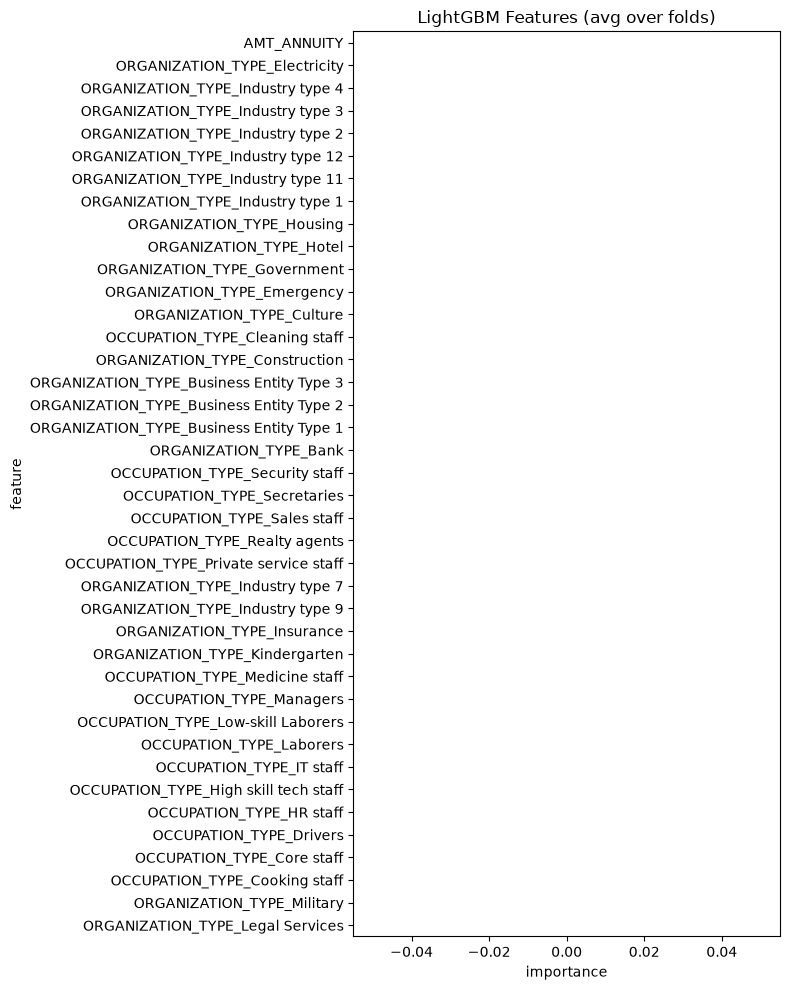

In [67]:
folder_path = Path('./data/')
debug = True
num_rows = 500 if debug else None
submission_file_name = "submission_kernel02.csv"

df = application_train_test(folder_path, num_rows)
with timer("Process bureau and bureau_balance"):
    bureau = bureau_and_balance(folder_path, num_rows)
    print("Bureau df shape:", bureau.shape)
    df = df.join(bureau, how='left', on='SK_ID_CURR')
    del bureau
    gc.collect()
with timer("Process previous_applications"):
    prev = previous_applications(folder_path, num_rows)
    print("Previous applications df shape:", prev.shape)
    df = df.join(prev, how='left', on='SK_ID_CURR')
    del prev
    gc.collect()
with timer("Process POS-CASH balance"):
    pos = pos_cash(folder_path, num_rows)
    print("Pos-cash balance df shape:", pos.shape)
    df = df.join(pos, how='left', on='SK_ID_CURR')
    del pos
    gc.collect()
with timer("Process installments payments"):
    ins = installments_payments(folder_path, num_rows)
    print("Installments payments df shape:", ins.shape)
    df = df.join(ins, how='left', on='SK_ID_CURR')
    del ins
    gc.collect()
with timer("Process credit card balance"):
    cc = credit_card_balance(folder_path, num_rows)
    print("Credit card balance df shape:", cc.shape)
    df = df.join(cc, how='left', on='SK_ID_CURR')
    del cc
    gc.collect()

#Dropping columns with too many missing
missing_ratio = df.isnull().mean()
cols_to_drop = missing_ratio[missing_ratio > 0.10].index.tolist()
cols_to_drop = [col for col in cols_to_drop if col != 'TARGET']

print(f"Dropping {len(cols_to_drop)} columns with more than 10% missing values")
df = df.drop(columns=cols_to_drop)
print("Updated df shape:", df.shape)

#Rename columns with any json special characters
df.columns = df.columns.str.replace('[\[\]\\\/\,\:]', '', regex=True)

with timer("Run LightGBM with kfold"):
    feat_importance = kfold_lightgbm(df, num_folds= 10, stratified= False, debug= debug)


In [8]:
df = pd.read_csv("processed_data.csv")

null_df = df.isnull().sum() / df.shape[0]
null_df.sort_values(ascending=False, inplace=True)
null_df.to_csv("null_df.csv", index=True)